# Final Model Comparison

This notebook compares the validation performance of all completed models in the project.

The main model-selection metric is **Macro-F1** because the Severity classes are highly imbalanced. Overall accuracy is included as a secondary metric.

The final model will be selected using **validation performance only**. Test results will be reported after the model is selected.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import json
import pandas as pd
import matplotlib.pyplot as plt

from src import config

In [7]:
def load_json(path):
    with open(path, "r") as f:
        return json.load(f)


validation_files = {
    "Logistic Regression": config.RESULTS_DIR / "lr_val.json",
    "Naive Bayes": config.RESULTS_DIR / "nb_val.json",
    "Decision Tree": config.RESULTS_DIR / "dt_val.json",
    "Random Forest": config.RESULTS_DIR / "rf_sampled_val.json",
    "XGBoost": config.RESULTS_DIR / "xgb_val.json",

    "Shallow NN": config.RESULTS_DIR / "neural_networks" / "shallow" / "val_metrics.json",
    "Wide NN": config.RESULTS_DIR / "neural_networks" / "wide" / "val_metrics.json",
    "Deep NN": config.RESULTS_DIR / "neural_networks" / "deep" / "val_metrics.json",
    "Regularized Deep NN": config.RESULTS_DIR / "neural_networks" / "regularized_deep" / "val_metrics.json",
    "Light Regularized Deep NN": config.RESULTS_DIR / "neural_networks" / "regularized_deep_light" / "val_metrics.json",
}


for model, path in validation_files.items():
    print(model, "->", path.exists())

Logistic Regression -> True
Naive Bayes -> True
Decision Tree -> True
Random Forest -> True
XGBoost -> True
Shallow NN -> True
Wide NN -> True
Deep NN -> True
Regularized Deep NN -> True
Light Regularized Deep NN -> True


In [ ]:
knn_path = config.RESULTS_DIR / "quick" / "knn_val.json"

print("KNN validation file ->", knn_path.exists())
print("Path:", knn_path)

In [2]:
from src.models import make_model, fit_model
from sklearn.metrics import f1_score, accuracy_score

knn_features = config.FEATURE_SETS["combined"]

knn_train = pd.read_parquet(config.TRAIN_SAMPLE_PARQUET).head(100_000)
knn_val = pd.read_parquet(config.VAL_PARQUET).head(100_000)

print("KNN train rows:", len(knn_train))
print("KNN validation rows:", len(knn_val))

KNN train rows: 100000
KNN validation rows: 100000


In [ ]:
from src.models import make_model, fit_model
from sklearn.metrics import f1_score, accuracy_score

knn_features = config.FEATURE_SETS["combined"]

knn_train = pd.read_parquet(config.TRAIN_SAMPLE_PARQUET).head(100_000)
knn_val = pd.read_parquet(config.VAL_PARQUET).head(100_000)

print("KNN train rows:", len(knn_train))
print("KNN validation rows:", len(knn_val))

In [ ]:
%pip install xgboost

In [3]:
knn_model = make_model(
    "knn",
    knn_features,
    model__n_neighbors=5,
    model__weights="distance"
)

knn_model = fit_model(
    knn_model,
    knn_train[knn_features],
    knn_train[config.TARGET],
    balanced=True
)

print("KNN training complete.")

KNN training complete.


In [4]:
knn_val_pred = knn_model.predict(knn_val[knn_features])

knn_val_accuracy = accuracy_score(
    knn_val[config.TARGET],
    knn_val_pred
)

knn_val_macro_f1 = f1_score(
    knn_val[config.TARGET],
    knn_val_pred,
    labels=config.CLASSES,
    average="macro",
    zero_division=0
)

print("KNN Validation Accuracy:", round(knn_val_accuracy, 4))
print("KNN Validation Macro-F1:", round(knn_val_macro_f1, 4))

KNN Validation Accuracy: 0.7275
KNN Validation Macro-F1: 0.2968


In [8]:
rows = []

for model, path in validation_files.items():
    result = load_json(path)

    rows.append({
        "Model": model,
        "Validation Accuracy": result["accuracy"],
        "Validation Macro-F1": result["macro_f1"]
    })

# Add KNN separately because its JSON file was not saved
rows.append({
    "Model": "KNN (100K)",
    "Validation Accuracy": knn_val_accuracy,
    "Validation Macro-F1": knn_val_macro_f1
})

comparison_df = pd.DataFrame(rows)

comparison_df = comparison_df.sort_values(
    "Validation Macro-F1",
    ascending=False
).reset_index(drop=True)

comparison_df.round(4)

,Model,Validation Accuracy,Validation Macro-F1
0,Decision Tree,0.7315,0.4149
1,Random Forest,0.7345,0.3967
2,Naive Bayes,0.7540,0.3261
3,XGBoost,0.5013,0.3188
4,KNN (100K),0.7275,0.2968
5,Deep NN,0.7900,0.2707
6,Wide NN,0.7896,0.2686
7,Shallow NN,0.7894,0.2576
8,Light Regularized Deep NN,0.7897,0.2519
9,Logistic Regression,0.3333,0.2373


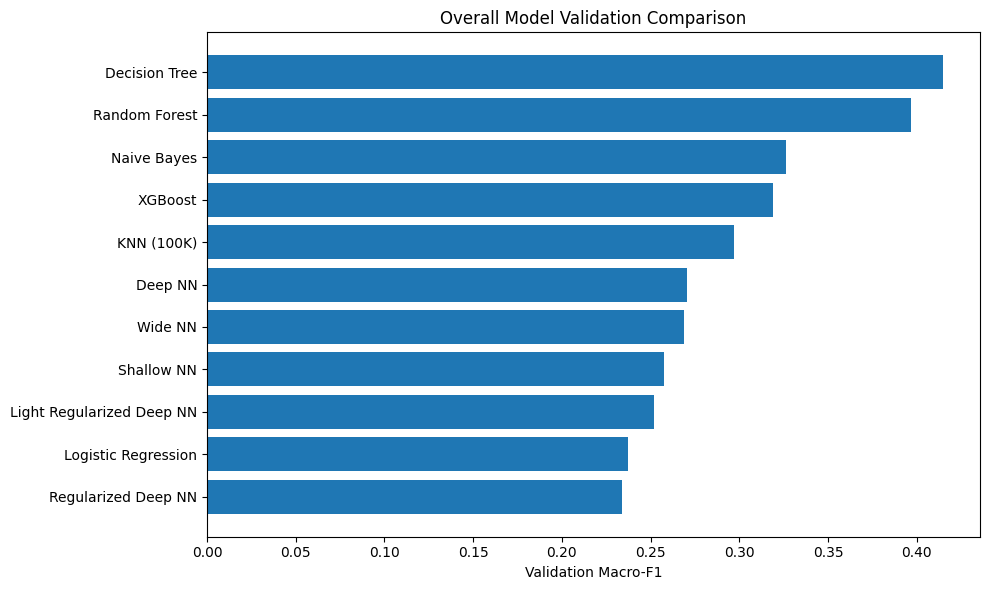

In [9]:
plt.figure(figsize=(10, 6))

plot_df = comparison_df.sort_values(
    "Validation Macro-F1",
    ascending=True
)

plt.barh(
    plot_df["Model"],
    plot_df["Validation Macro-F1"]
)

plt.xlabel("Validation Macro-F1")
plt.title("Overall Model Validation Comparison")
plt.tight_layout()

plt.show()

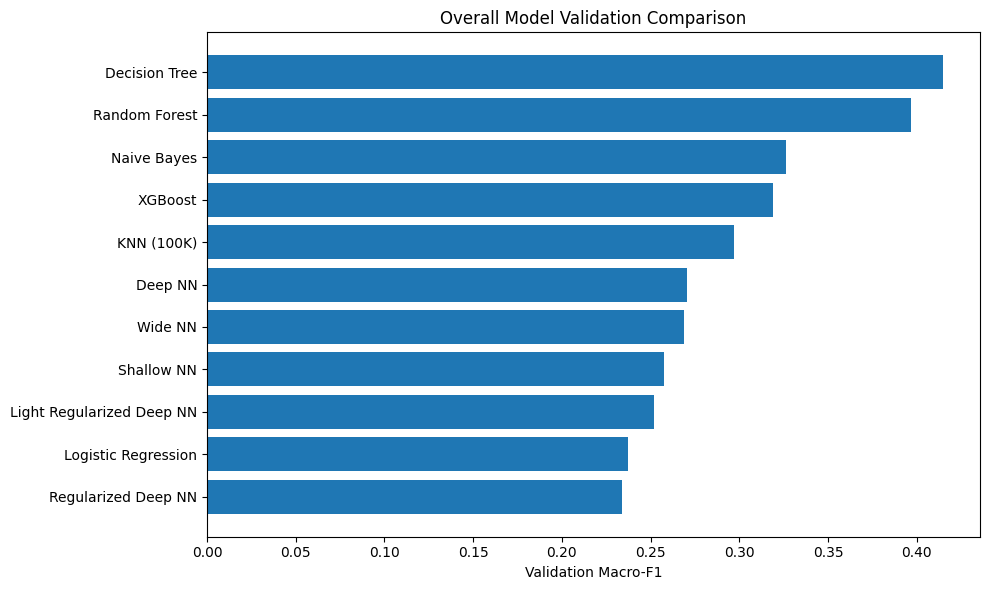

Comparison table and figure saved.


In [10]:
comparison_df.to_csv(
    config.RESULTS_DIR / "final_model_validation_comparison.csv",
    index=False
)

plt.figure(figsize=(10, 6))

plot_df = comparison_df.sort_values(
    "Validation Macro-F1",
    ascending=True
)

plt.barh(
    plot_df["Model"],
    plot_df["Validation Macro-F1"]
)

plt.xlabel("Validation Macro-F1")
plt.title("Overall Model Validation Comparison")
plt.tight_layout()

plt.savefig(
    config.FIGURES_DIR / "final_model_validation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison table and figure saved.")

## Final Model Selection

The final model was selected using validation Macro-F1 because the accident severity classes are highly imbalanced.

The **Decision Tree** achieved the highest validation Macro-F1 of **0.4149**, followed by Random Forest at **0.3967**.

Therefore, the **Decision Tree was selected as the final model**.

Although the Decision Tree achieved the best validation performance, earlier analysis showed that some test records have feature patterns identical to records in the training set. This suggests that part of the Decision Tree's performance may come from memorizing repeated patterns. This limitation will be discussed in the final report.

In [11]:
dt_test_path = config.RESULTS_DIR / "dt_test.json"

dt_test = load_json(dt_test_path)

print("Decision Tree Test Accuracy:", round(dt_test["accuracy"], 4))
print("Decision Tree Test Macro-F1:", round(dt_test["macro_f1"], 4))

print("\nPer-class F1:")
for severity, metrics in dt_test["per_class"].items():
    print(f"Severity {severity}: {metrics['f1']:.4f}")

Decision Tree Test Accuracy: 0.7317
Decision Tree Test Macro-F1: 0.4139

Per-class F1:
Severity 1: 0.2276
Severity 2: 0.8373
Severity 3: 0.3531
Severity 4: 0.2378


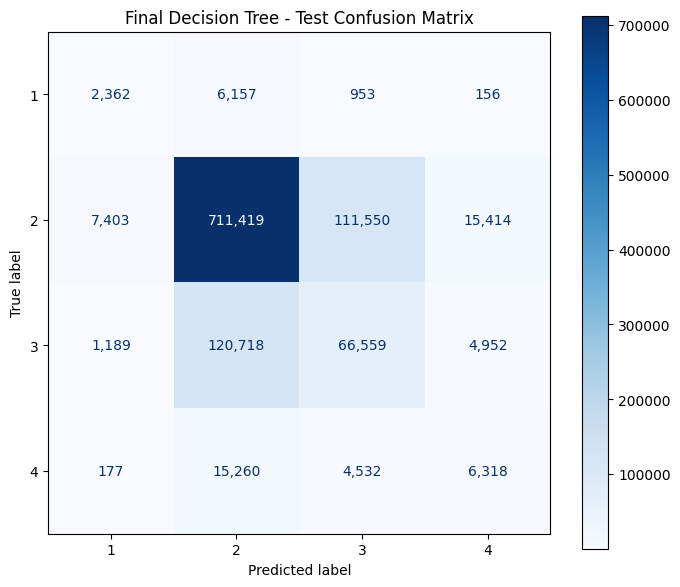

In [12]:
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

cm = np.array(dt_test["confusion_matrix"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=config.CLASSES
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", values_format=",d")

ax.set_title("Final Decision Tree - Test Confusion Matrix")

plt.tight_layout()

plt.savefig(
    config.FIGURES_DIR / "final_decision_tree_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

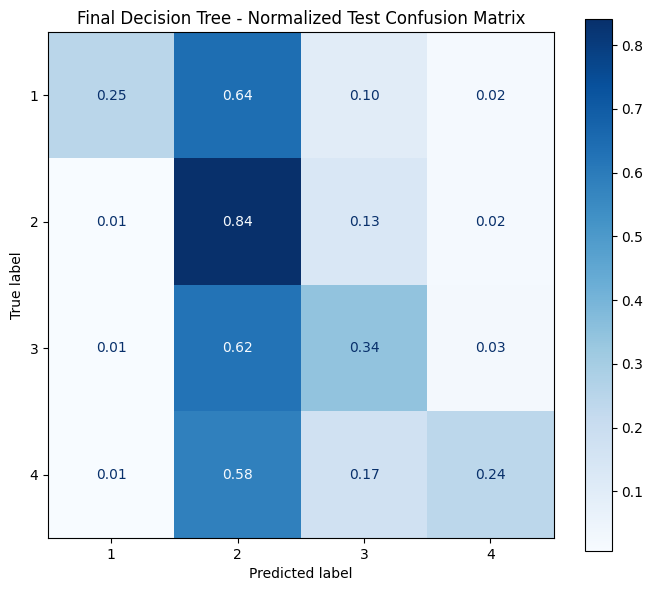

In [13]:
cm_normalized = cm.astype("float") / cm.sum(axis=1)[:, None]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=config.CLASSES
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f"
)

ax.set_title("Final Decision Tree - Normalized Test Confusion Matrix")

plt.tight_layout()

plt.savefig(
    config.FIGURES_DIR / "final_decision_tree_confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Final Model Test Performance

The Decision Tree achieved a **test Macro-F1 of 0.4139** and a **test accuracy of 0.7317**.

Its validation Macro-F1 was 0.4149, which is very close to the test result. This indicates that the model's overall performance remained stable on unseen test data.

However, the normalized confusion matrix shows that the model performs much better on Severity 2 than on the minority classes. Severity 1, 3, and 4 accidents are frequently misclassified as Severity 2.

This reflects the strong class imbalance in the dataset and remains an important limitation of the final model.